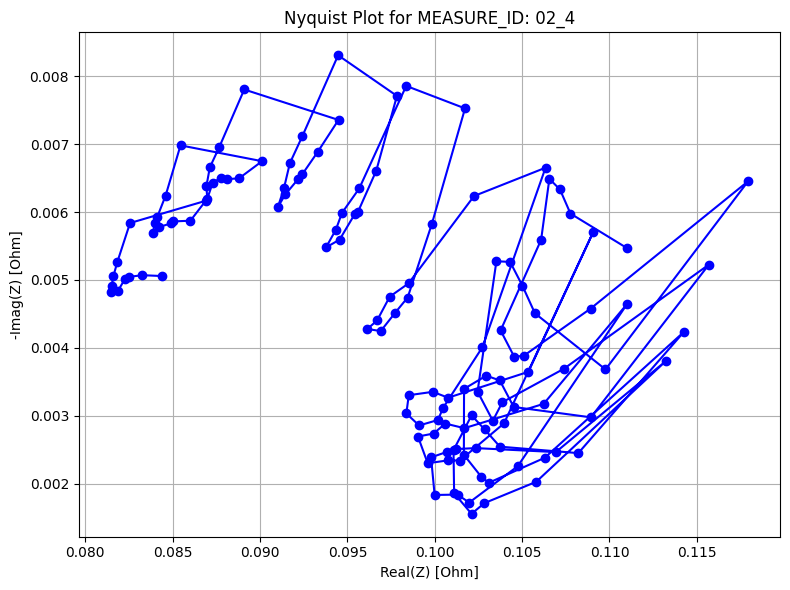

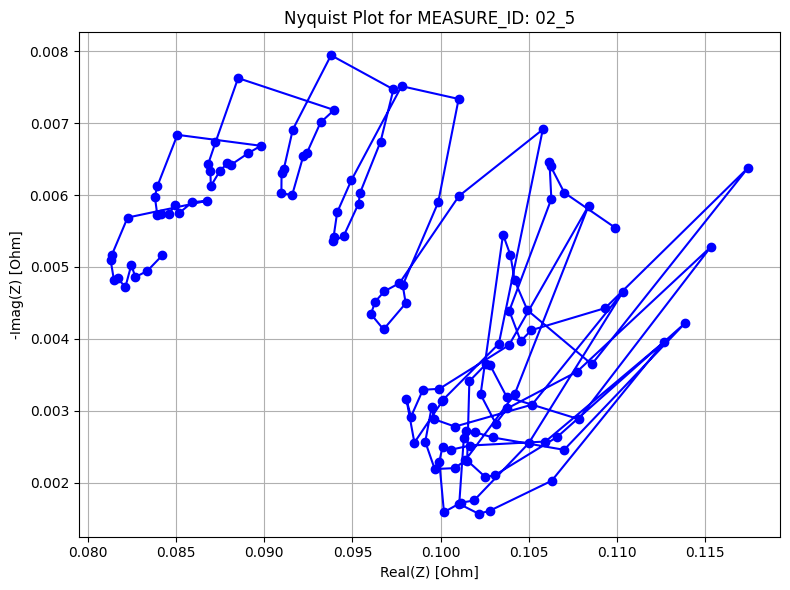

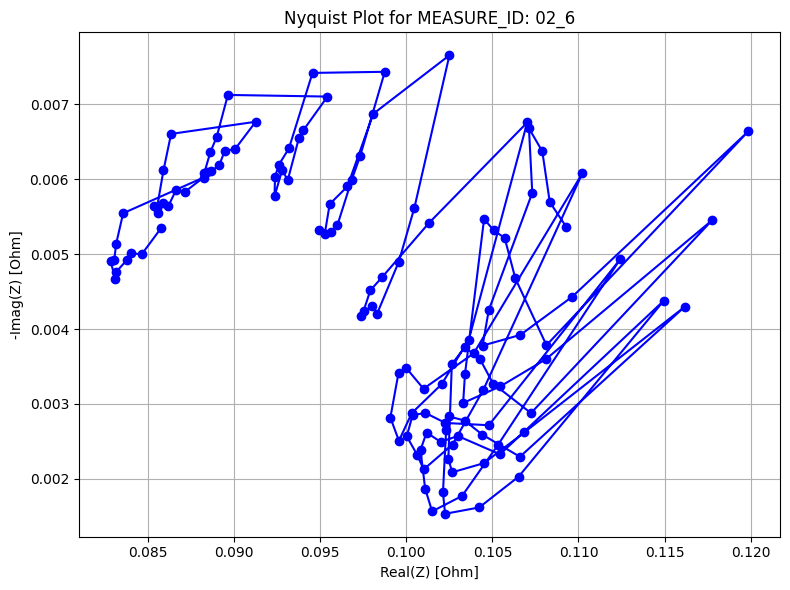

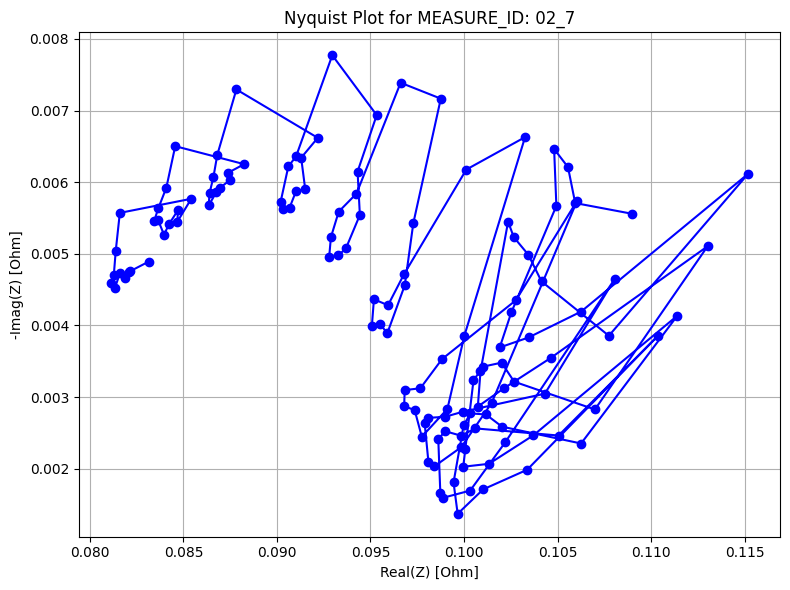

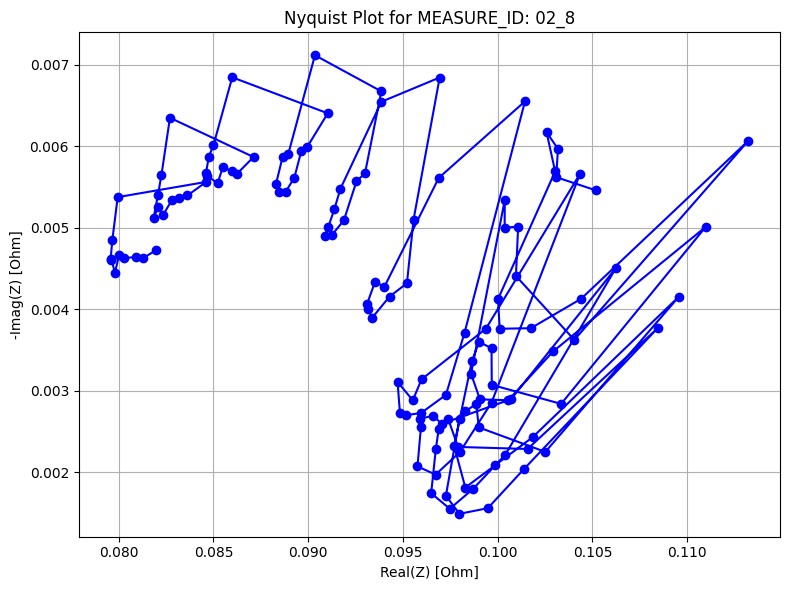

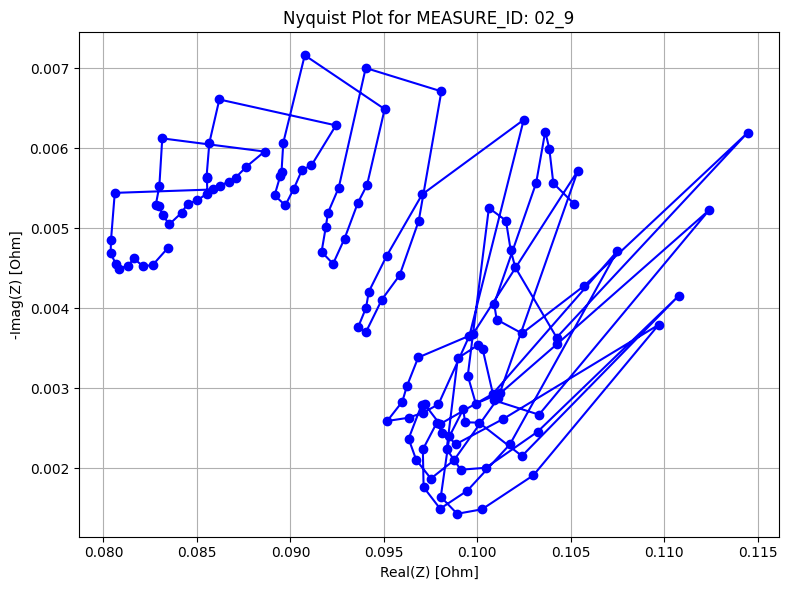

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("BatteryID02.csv")

# Convert string complex numbers to actual complex values
df["IMPEDANCE_VALUE"] = df["IMPEDANCE_VALUE"].apply(lambda x: complex(x.strip("()")))

# Sort and group by MEASURE_ID to extract spectra
spectra = (
    df.sort_values(by=["MEASURE_ID", "FREQUENCY_ID"])
    .groupby("MEASURE_ID")["IMPEDANCE_VALUE"]
    .apply(list)
)

# Loop through each MEASURE_ID and show plots one-by-one
for measure_id, impedance_list in spectra.items():
    real_parts = [z.real for z in impedance_list]
    imag_parts = [z.imag for z in impedance_list]

    plt.figure(figsize=(8, 6))
    plt.plot(real_parts, -1 * np.array(imag_parts), marker='o', color='blue')
    plt.title(f"Nyquist Plot for MEASURE_ID: {measure_id}")
    plt.xlabel("Real(Z) [Ohm]")
    plt.ylabel("-Imag(Z) [Ohm]")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


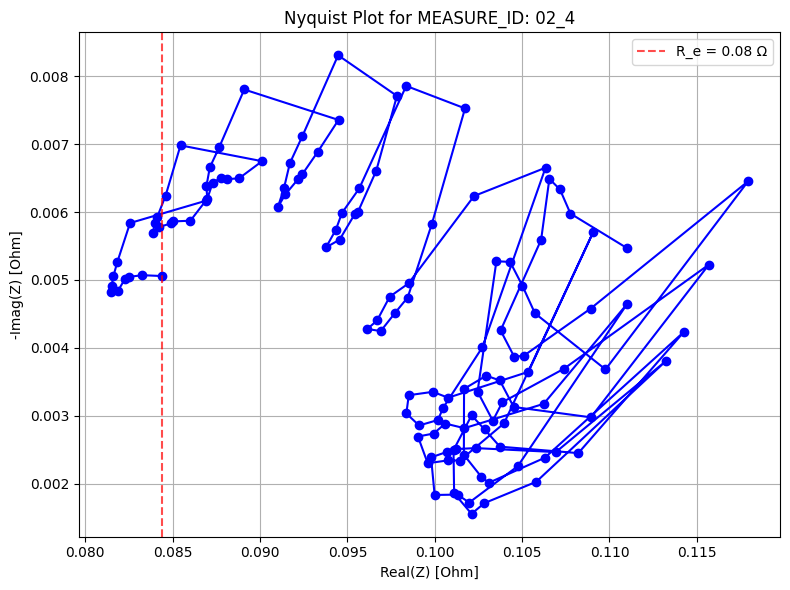

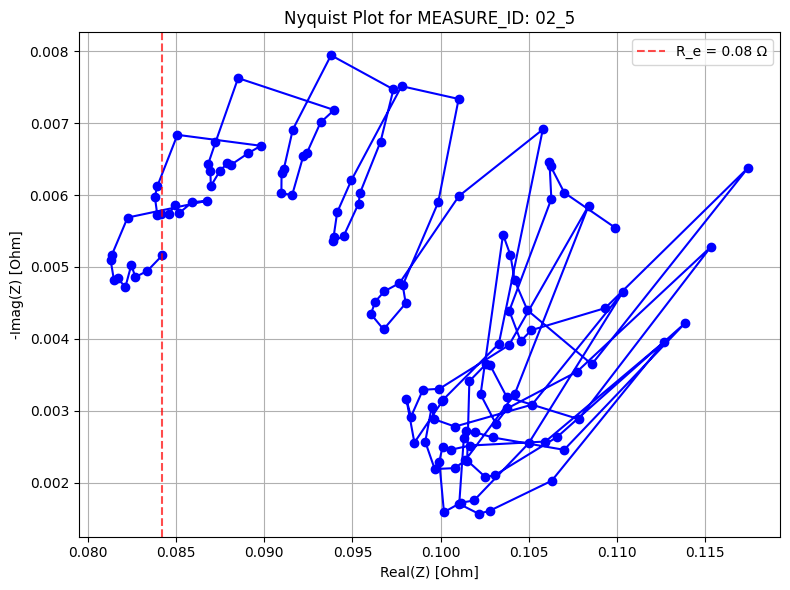

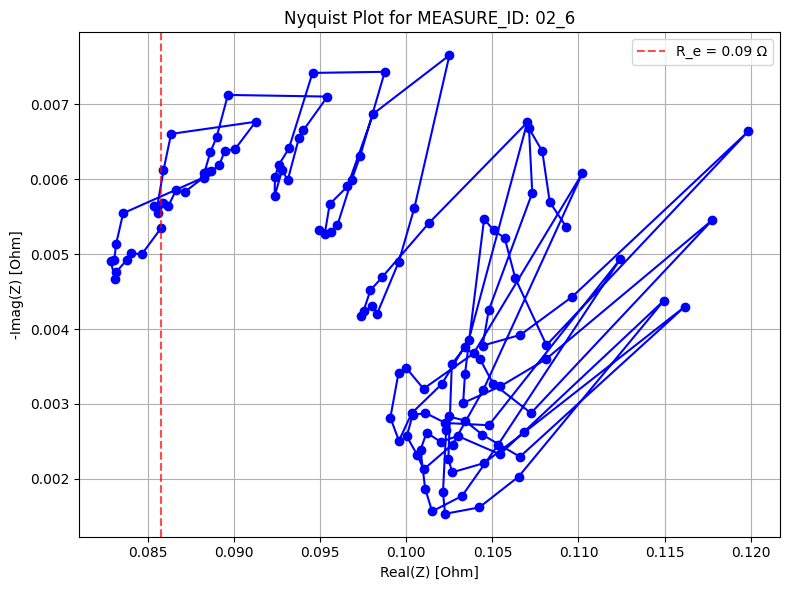

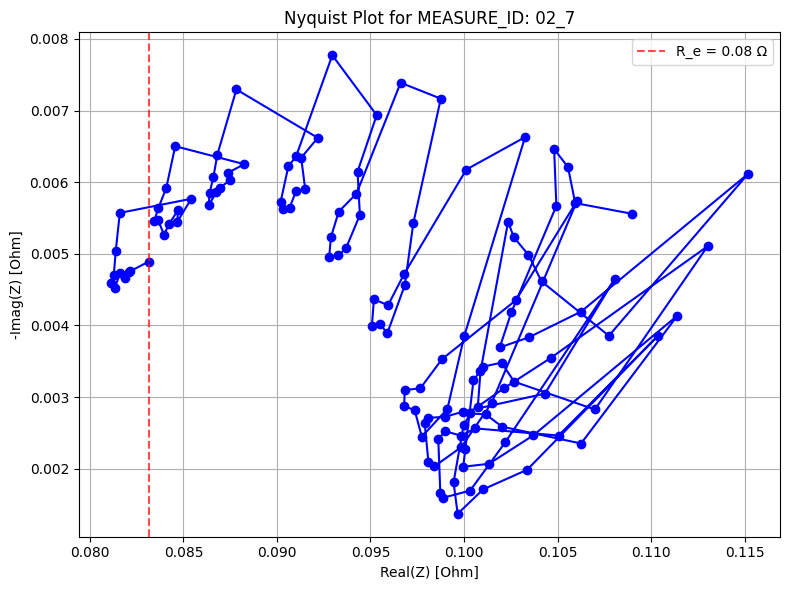

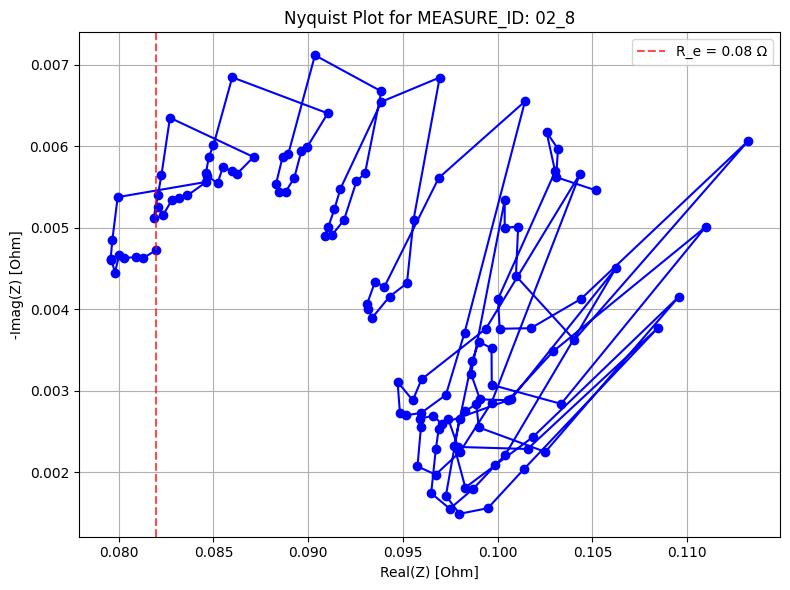

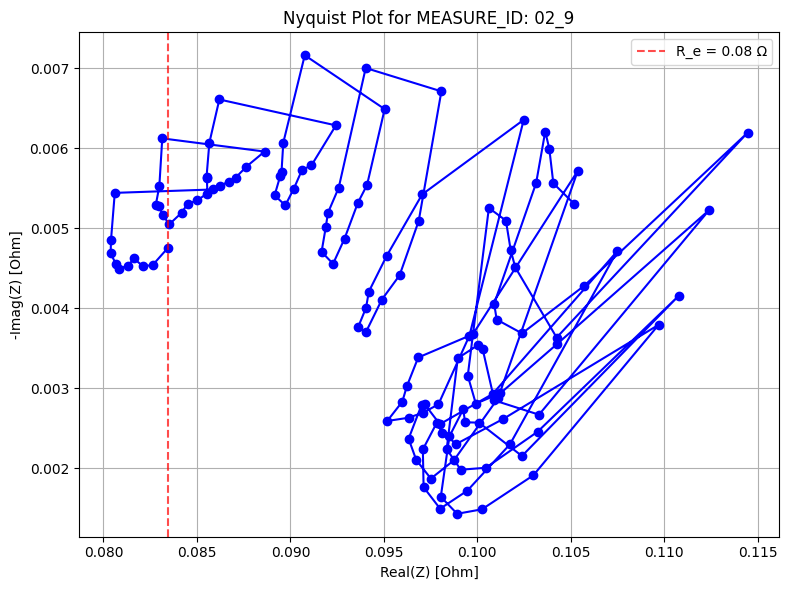

  MEASURE_ID  R_electrolyte  R_charge_transfer  Min_Imaginary  Max_Real
0       02_4       0.084373           0.010097      -0.008309  0.117933
1       02_5       0.084208           0.009576      -0.007943  0.117446
2       02_6       0.085772           0.016732      -0.007653  0.119855
3       02_7       0.083137           0.009821      -0.007772  0.115191
4       02_8       0.081982           0.008376      -0.007113  0.113213
5       02_9       0.083441           0.007328      -0.007163  0.114456


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Your existing code...
df = pd.read_csv("BatteryID02.csv")
df["IMPEDANCE_VALUE"] = df["IMPEDANCE_VALUE"].apply(lambda x: complex(x.strip("()")))
spectra = (
    df.sort_values(by=["MEASURE_ID", "FREQUENCY_ID"])
    .groupby("MEASURE_ID")["IMPEDANCE_VALUE"]
    .apply(list)
)

# Extract frequencies as well
frequencies = (
    df.sort_values(by=["MEASURE_ID", "FREQUENCY_ID"])
    .groupby("MEASURE_ID")["FREQUENCY_ID"]
    .apply(list)
)

# Create a list to store analysis results
analysis_results = []

for measure_id, impedance_list in spectra.items():
    freq_list = frequencies[measure_id]
    real_parts = [z.real for z in impedance_list]
    imag_parts = [z.imag for z in impedance_list]
    
    # Basic parameters
    min_imag_index = np.argmin(imag_parts)  # Maximum of -imaginary part
    r_e = real_parts[-1]  # High frequency intercept (electrolyte resistance)
    r_ct = real_parts[min_imag_index] - r_e  # Charge transfer resistance
    
    # Store results
    analysis_results.append({
        'MEASURE_ID': measure_id,
        'R_electrolyte': r_e,
        'R_charge_transfer': r_ct,
        'Min_Imaginary': min(imag_parts),
        'Max_Real': max(real_parts)
    })
    
    # Your existing plotting code
    plt.figure(figsize=(8, 6))
    plt.plot(real_parts, -1 * np.array(imag_parts), marker='o', color='blue')
    plt.axvline(x=r_e, color='red', linestyle='--', alpha=0.7, label=f'R_e = {r_e:.2f} Ω')
    plt.title(f"Nyquist Plot for MEASURE_ID: {measure_id}")
    plt.xlabel("Real(Z) [Ohm]")
    plt.ylabel("-Imag(Z) [Ohm]")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Convert results to DataFrame
results_df = pd.DataFrame(analysis_results)
print(results_df)